# Load Data from Data Preparation

In [ ]:
!wget https://raw.githubusercontent.com/azzaauliyaul/Detection-of-Stunting-in-Indonesian-Toddlers/main/data/preprocessed_stunting_data.joblib

--2026-11-24 15:19:50--  https://raw.githubusercontent.com/azzaauliyaul/Detection-of-Stunting-in-Indonesian-Toddlers/main/data/preprocessed_stunting_data.joblib
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1580322 (1.5M) [application/octet-stream]
Saving to: ‘preprocessed_stunting_data.joblib’

preprocessed_stunti 100%[===================>]   1.51M  --.-KB/s    in 0.06s   

2026-11-24 15:19:50 (26.5 MB/s) - ‘preprocessed_stunting_data.joblib’ saved [1580322/1580322]



In [ ]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

In [ ]:
data = joblib.load("preprocessed_stunting_data.joblib")

X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val     = data["X_val"], data["y_val"]
X_test, y_test   = data["X_test"], data["y_test"]
target_encoder   = data["target_encoder"]
class_weights    = data["class_weights"]
RANDOM_STATE     = data["random_state"]

print(f"Loaded! Train: {len(X_train):,} | Val: {len(X_val):,} | Test: {len(X_test):,}")
print("Target Mapping:", dict(enumerate(target_encoder.classes_)))
print("Class Weights :", class_weights)

Loaded! Train: 27,597 | Val: 5,914 | Test: 5,914
Target Mapping: {0: 'normal', 1: 'severely stunted', 2: 'stunted', 3: 'tinggi'}
Class Weights : {0: 0.45814795139119463, 1: 1.5116673970201577, 2: 2.23132276843467, 3: 1.4132015567390415}


# Model Random Forest Classifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_time = time.time()
rf_model.fit(X_train, y_train)
train_time = time.time() - start_time

print("=== KONFIGURASI HYPERPARAMETER AWAL (RANDOM FOREST) ===")
for param, val in rf_model.get_params().items():
    print(f"{param:22s}: {val}")
print(f"\nWaktu Pelatihan: {train_time:.4f} detik")

=== KONFIGURASI HYPERPARAMETER AWAL (RANDOM FOREST) ===
bootstrap             : True
ccp_alpha             : 0.0
class_weight          : balanced
criterion             : gini
max_depth             : None
max_features          : sqrt
max_leaf_nodes        : None
max_samples           : None
min_impurity_decrease : 0.0
min_samples_leaf      : 1
min_samples_split     : 2
min_weight_fraction_leaf: 0.0
monotonic_cst         : None
n_estimators          : 100
n_jobs                : -1
oob_score             : False
random_state          : 42
verbose               : 0
warm_start            : False

Waktu Pelatihan: 1.0502 detik


In [ ]:
y_train_pred = rf_model.predict(X_train)
y_val_pred = rf_model.predict(X_val)

train_acc = accuracy_score(y_train, y_train_pred)
val_acc = accuracy_score(y_val, y_val_pred)
val_macro_f1 = f1_score(y_val, y_val_pred, average="macro")
val_weighted_f1 = f1_score(y_val, y_val_pred, average="weighted")
val_macro_prec = precision_score(y_val, y_val_pred, average="macro")
val_macro_rec = recall_score(y_val, y_val_pred, average="macro")

print("=== RINGKASAN SKOR VALIDATION SET (RANDOM FOREST INITIAL) ===")
print(f"Train Accuracy      : {train_acc:.4f}")
print(f"Val Accuracy        : {val_acc:.4f}")
print(f"Selisih Overfit     : {train_acc - val_acc:.4f}")
print(f"Val Macro F1-Score  : {val_macro_f1:.4f}")
print(f"Val Weighted F1     : {val_weighted_f1:.4f}")
print(f"Val Macro Precision : {val_macro_prec:.4f}")
print(f"Val Macro Recall    : {val_macro_rec:.4f}")

print("\n=== CLASSIFICATION REPORT (VALIDATION SET) ===")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=target_encoder.classes_,
    digits=4
))

=== RINGKASAN SKOR VALIDATION SET (RANDOM FOREST INITIAL) ===
Train Accuracy      : 1.0000
Val Accuracy        : 0.9899
Selisih Overfit     : 0.0101
Val Macro F1-Score  : 0.9865
Val Weighted F1     : 0.9899
Val Macro Precision : 0.9866
Val Macro Recall    : 0.9863

=== CLASSIFICATION REPORT (VALIDATION SET) ===
                  precision    recall  f1-score   support

          normal     0.9929    0.9944    0.9937      3227
severely stunted     0.9908    0.9898    0.9903       978
         stunted     0.9715    0.9774    0.9744       663
          tinggi     0.9913    0.9837    0.9875      1046

        accuracy                         0.9899      5914
       macro avg     0.9866    0.9863    0.9865      5914
    weighted avg     0.9899    0.9899    0.9899      5914



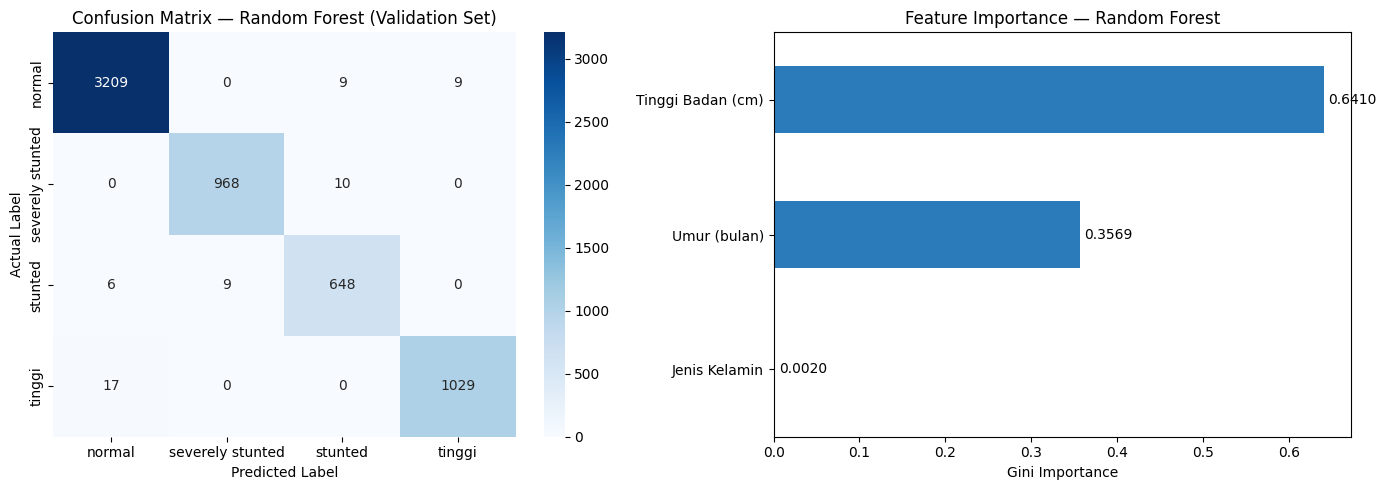

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_val, y_val_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_,
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix — Random Forest (Validation Set)")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values()
importances.plot(kind="barh", color="#2b7bba", ax=axes[1])
axes[1].set_title("Feature Importance — Random Forest")
axes[1].set_xlabel("Gini Importance")
for i, v in enumerate(importances):
    axes[1].text(v + 0.005, i, f"{v:.4f}", va="center")

plt.tight_layout()
plt.savefig("rf_initial_validation.png", dpi=300, bbox_inches="tight")
plt.show()

# Model XGBoost Classifier

In [ ]:
from xgboost import XGBClassifier

sample_weights_train = np.array([class_weights[label] for label in y_train])

xgb_model = XGBClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_time = time.time()
xgb_model.fit(X_train, y_train, sample_weight=sample_weights_train)
train_time = time.time() - start_time

print(f"Training selesai dalam {train_time:.4f} detik")

Training selesai dalam 0.5736 detik


In [ ]:
y_train_pred = xgb_model.predict(X_train)
y_val_pred = xgb_model.predict(X_val)

train_acc = accuracy_score(y_train, y_train_pred)
val_acc = accuracy_score(y_val, y_val_pred)
val_macro_f1 = f1_score(y_val, y_val_pred, average="macro")
val_weighted_f1 = f1_score(y_val, y_val_pred, average="weighted")
val_macro_prec = precision_score(y_val, y_val_pred, average="macro")
val_macro_rec = recall_score(y_val, y_val_pred, average="macro")

print("=== RINGKASAN SKOR VALIDATION SET (XGBOOST INITIAL) ===")
print(f"Train Accuracy      : {train_acc:.4f}")
print(f"Val Accuracy        : {val_acc:.4f}")
print(f"Selisih Overfit     : {train_acc - val_acc:.4f}")
print(f"Val Macro F1-Score  : {val_macro_f1:.4f}")
print(f"Val Weighted F1     : {val_weighted_f1:.4f}")
print(f"Val Macro Precision : {val_macro_prec:.4f}")
print(f"Val Macro Recall    : {val_macro_rec:.4f}")

print("\n=== CLASSIFICATION REPORT (VALIDATION SET) ===")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=target_encoder.classes_,
    digits=4
))

=== RINGKASAN SKOR VALIDATION SET (XGBOOST INITIAL) ===
Train Accuracy      : 0.9870
Val Accuracy        : 0.9777
Selisih Overfit     : 0.0093
Val Macro F1-Score  : 0.9711
Val Weighted F1     : 0.9779
Val Macro Precision : 0.9628
Val Macro Recall    : 0.9801

=== CLASSIFICATION REPORT (VALIDATION SET) ===
                  precision    recall  f1-score   support

          normal     0.9952    0.9727    0.9839      3227
severely stunted     0.9837    0.9867    0.9852       978
         stunted     0.8997    0.9744    0.9356       663
          tinggi     0.9727    0.9866    0.9796      1046

        accuracy                         0.9777      5914
       macro avg     0.9628    0.9801    0.9711      5914
    weighted avg     0.9786    0.9777    0.9779      5914



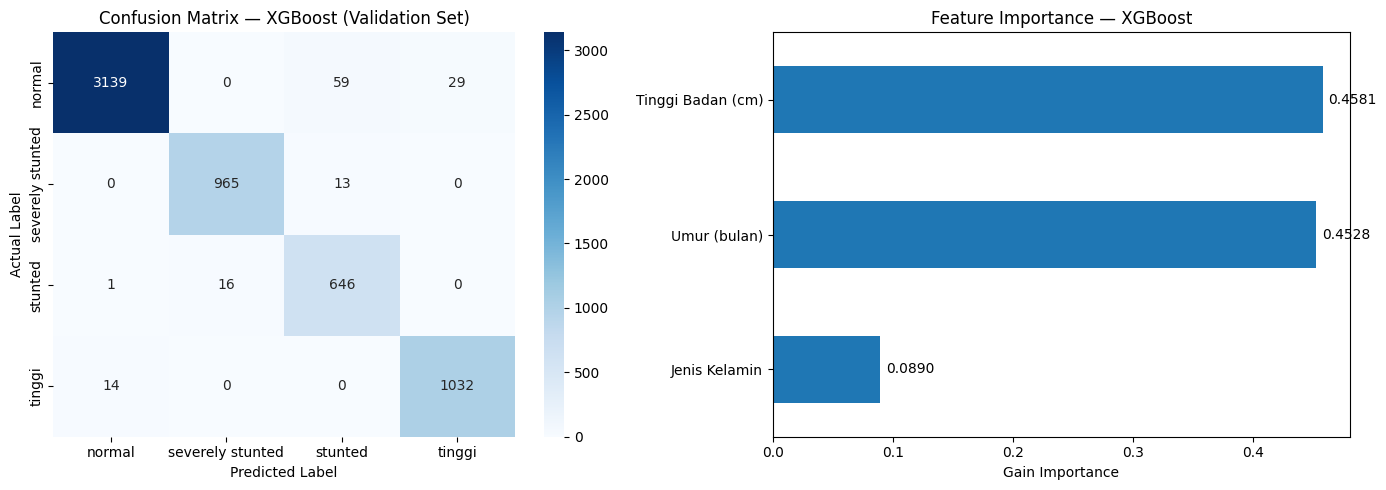

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_val, y_val_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_,
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix — XGBoost (Validation Set)")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

importances = pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values()
importances.plot(kind="barh", color="#1f77b4", ax=axes[1])
axes[1].set_title("Feature Importance — XGBoost")
axes[1].set_xlabel("Gain Importance")
for i, v in enumerate(importances):
    axes[1].text(v + 0.005, i, f"{v:.4f}", va="center")

plt.tight_layout()
plt.savefig("xgb_initial_validation.png", dpi=300, bbox_inches="tight")
plt.show()

# Model lightGBM Classifier

In [ ]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)

start_time = time.time()
lgbm_model.fit(X_train, y_train)
train_time_lgbm = time.time() - start_time

print(f"Training selesai dalam {train_time_lgbm:.4f} detik")

Training selesai dalam 0.6014 detik


In [ ]:
y_train_pred_lgbm = lgbm_model.predict(X_train)
y_val_pred_lgbm = lgbm_model.predict(X_val)

train_acc_lgbm = accuracy_score(y_train, y_train_pred_lgbm)
val_acc_lgbm = accuracy_score(y_val, y_val_pred_lgbm)
val_macro_f1_lgbm = f1_score(y_val, y_val_pred_lgbm, average="macro")
val_weighted_f1_lgbm = f1_score(y_val, y_val_pred_lgbm, average="weighted")
val_macro_prec_lgbm = precision_score(y_val, y_val_pred_lgbm, average="macro")
val_macro_rec_lgbm = recall_score(y_val, y_val_pred_lgbm, average="macro")

print("=== RINGKASAN SKOR VALIDATION SET (LIGHTGBM INITIAL) ===")
print(f"Train Accuracy      : {train_acc_lgbm:.4f}")
print(f"Val Accuracy        : {val_acc_lgbm:.4f}")
print(f"Selisih Overfit     : {train_acc_lgbm - val_acc_lgbm:.4f}")
print(f"Val Macro F1-Score  : {val_macro_f1_lgbm:.4f}")
print(f"Val Weighted F1     : {val_weighted_f1_lgbm:.4f}")
print(f"Val Macro Precision : {val_macro_prec_lgbm:.4f}")
print(f"Val Macro Recall    : {val_macro_rec_lgbm:.4f}")

print("\n=== CLASSIFICATION REPORT (VALIDATION SET) ===")
print(classification_report(
    y_val,
    y_val_pred_lgbm,
    target_names=target_encoder.classes_,
    digits=4
))

=== RINGKASAN SKOR VALIDATION SET (LIGHTGBM INITIAL) ===
Train Accuracy      : 0.9814
Val Accuracy        : 0.9713
Selisih Overfit     : 0.0101
Val Macro F1-Score  : 0.9620
Val Weighted F1     : 0.9719
Val Macro Precision : 0.9505
Val Macro Recall    : 0.9762

=== CLASSIFICATION REPORT (VALIDATION SET) ===
                  precision    recall  f1-score   support

          normal     0.9968    0.9631    0.9797      3227
severely stunted     0.9875    0.9703    0.9789       978
         stunted     0.8451    0.9789    0.9071       663
          tinggi     0.9728    0.9924    0.9825      1046

        accuracy                         0.9713      5914
       macro avg     0.9505    0.9762    0.9620      5914
    weighted avg     0.9740    0.9713    0.9719      5914



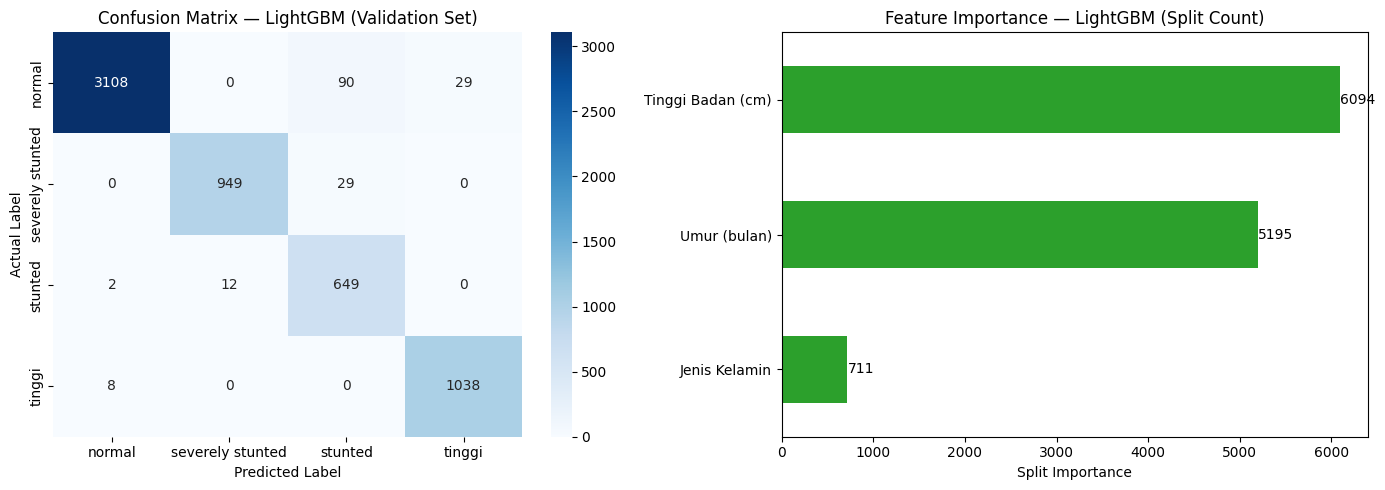

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_lgbm = confusion_matrix(y_val, y_val_pred_lgbm)
sns.heatmap(
    cm_lgbm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_,
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix — LightGBM (Validation Set)")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

importances_lgbm = pd.Series(lgbm_model.feature_importances_, index=X_train.columns).sort_values()
importances_lgbm.plot(kind="barh", color="#2ca02c", ax=axes[1])
axes[1].set_title("Feature Importance — LightGBM (Split Count)")
axes[1].set_xlabel("Split Importance")
for i, v in enumerate(importances_lgbm):
    axes[1].text(v + 5, i, f"{v}", va="center")

plt.tight_layout()
plt.savefig("lgbm_initial_validation.png", dpi=300, bbox_inches="tight")
plt.show()